In [7]:
# Initialize the Julia environment

# swithch to the directory where this script is located
cd(@__DIR__)
# Packages
using Pkg
Pkg.activate(".")

#Pkg.instantiate() # uncomment if you want to install the packages

# Load the required packages
using Flux
using Zygote
using BSON
using Plots, Measures
using JLD2
using ProgressMeter
using ComponentArrays
using StatsBase

include("..//src//Surge.jl")
using .Surge  # Import all exported symbols from Surge module


# optional gpu usage
const use_gpu = false
if use_gpu
    using cuDNN, CUDA
    CUDA.allowscalar(false) # disable scalar operations on GPU
    if CUDA.functional() # check if CUDA is functional
        println("CUDA is functional, using GPU")
    else
        error("CUDA is not functional, using CPU")
    end
end

  Activating project at `c:\Users\britolim\OneDrive - Stichting Deltares\Desktop\Surge 9-4\Starting_networks`


In [8]:
# Data and model files
data_path = Surge.get_data_path()
model_path = Surge.get_model_path()
target_file = "wave1d_itide3.jld2"
pretrained_model_file = "source_surge_model_tide_ens.bson"

"source_surge_model_tide_ens.bson"

In [13]:
solution, grid, times, params = Surge.load_burgers_ensemble(target_file, data_path=data_path)
solution = [solution]
X, Y, n_steps = Surge.prepare_training_data(solution, params)


(X = Float32[0.0 0.0 … 0.0010497853 0.0; 0.0 0.0 … 0.0010497853 0.0; … ; 0.0 0.0 … 0.0010497853 0.0; 0.0 0.0 … 0.0010497853 0.0;;; -2.4105457f-6 0.0 … 0.014178853 0.0; -2.5760233f-8 1.8838959f-5 … 0.014178853 0.0; … ; 2.410546f-6 1.8838955f-5 … 0.014178853 0.0; 0.0 0.0 … 0.014178853 0.0;;; -1.7284416f-5 0.0 … 0.027306166 0.0; -2.868973f-7 6.831155f-5 … 0.027306166 0.0; … ; 1.7284436f-5 6.8311485f-5 … 0.027306166 0.0; 0.0 0.0 … 0.027306166 0.0;;; … ;;; 2.128155 0.0 … -0.039259817 0.0; 2.124846 0.041736618 … -0.039259817 0.0; … ; -1.9888835 0.010936635 … -0.039259817 0.0; 0.0 0.0 … -0.039259817 0.0;;; 2.1102786 0.0 … -0.026176948 0.0; 2.1070862 0.04262271 … -0.026176948 0.0; … ; -1.9854593 0.011830537 … -0.026176948 0.0; 0.0 0.0 … -0.026176948 0.0;;; 2.0920508 0.0 … -0.013089595 0.0; 2.0889788 0.04350173 … -0.013089595 0.0; … ; -1.981765 0.012723712 … -0.013089595 0.0; 0.0 0.0 … -0.013089595 0.0], Y = Float32[-2.4105457f-6 0.0; -2.5760233f-8 1.8838959f-5; … ; 2.410546f-6 1.8838955f-5; 0.

In [14]:
model = Surge.load_model(joinpath(model_path, pretrained_model_file))


ResidualBlock(
  Chain(
    Conv((3,), 5 => 16, swish, pad=1),  # 256 parameters
    Conv((3,), 16 => 16, swish, pad=1),  # 784 parameters
    Conv((3,), 16 => 16, swish, pad=1),  # 784 parameters
    Conv((3,), 16 => 16, swish, pad=1),  # 784 parameters
    Conv((3,), 16 => 2, pad=1),         # 98 parameters
  ),
  2,
)                   # Total: 10 arrays, 2_706 parameters, 11.328 KiB.

In [15]:
Y_unroll = Surge.unroll(model, X, 2, 1/1017, 720/720)
errors = Surge.compute_rollout_error(Y_unroll, Y, 2)
mean_err = vec(mean(errors, dims=2))
println("Mean rollout MSE per channel: ", mean_err)

Mean rollout MSE per channel: Float32[0.32218793, 0.16520873]


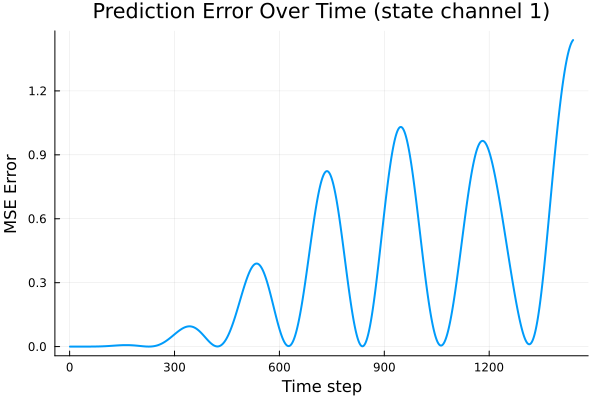

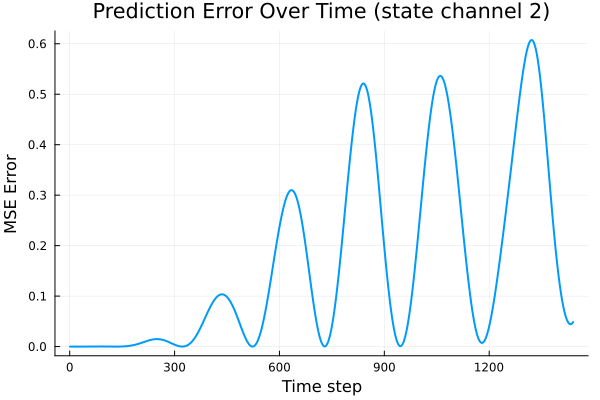

In [21]:
errors = Surge.compute_rollout_error(Y_unroll, Y, 2)
for ch in 1:2
    display(Surge.plot_error_over_time(errors[ch, :], title="Prediction Error Over Time (state channel $ch)"))
end